# Example 15.3 – PID Gain Optimization with GA
**Chapter 15 – PID Control Applied to Four-Bar Mechanisms**
Pure GA (NumPy only) minimizes the ISE to find optimal Kp, Ki, Kd.

In [1]:
from numpy import *
import matplotlib.pyplot as plt


## Evaluation function (ISE over full simulation)

In [2]:
def sim_pid_ise(Kp, Ki, Kd, t_end=5.0, dt=0.01, I=0.05, b=0.10):
    t = arange(0, t_end, dt)
    theta = zeros(len(t)); omega = zeros(len(t))
    e_int, e_prev = 0.0, 0.0
    ref = pi / 3
    for k in range(1, len(t)):
        e = ref - theta[k-1]
        e_int += e*dt; de = (e-e_prev)/dt
        u = Kp*e + Ki*e_int + Kd*de
        alpha = (u - b*omega[k-1])/I
        omega[k] = omega[k-1] + alpha*dt
        theta[k] = theta[k-1] + omega[k]*dt
        e_prev = e
    e_vec = degrees(ref) - degrees(theta)
    return trapezoid(e_vec**2, t)

## Genetic Algorithm (NumPy only)

In [3]:
random.seed(0)
N_pop, N_gen = 60, 120
bounds = array([[0.1, 20.0],[0.0, 30.0],[0.0, 2.0]])
pop = random.uniform(bounds[:,0], bounds[:,1], (N_pop, 3))

best_ise_hist = []
for gen in range(N_gen):
    fitness = array([sim_pid_ise(*ind) for ind in pop])
    idx = argsort(fitness)
    pop = pop[idx]
    best_ise_hist.append(fitness[idx[0]])
    elite = pop[:N_pop//2]
    children = []
    for _ in range(N_pop - len(elite)):
        p1, p2 = elite[random.randint(0, len(elite), 2)]
        alpha_c = random.uniform(0, 1, 3)
        child = alpha_c*p1 + (1-alpha_c)*p2
        if random.rand() < 0.15:
            child += random.randn(3) * (bounds[:,1]-bounds[:,0]) * 0.05
        child = clip(child, bounds[:,0], bounds[:,1])
        children.append(child)
    pop = vstack([elite, array(children)])

Kp_opt, Ki_opt, Kd_opt = pop[0]
print(f'Kp={Kp_opt:.3f}  Ki={Ki_opt:.3f}  Kd={Kd_opt:.4f}')
print(f'Optimal ISE = {best_ise_hist[-1]:.4f} (°²·s)')

# Dynamic calculation of initial ISE for real improvement comparison
ise_initial = sim_pid_ise(5.0, 1.0, 0.05)
improvement = ((ise_initial - best_ise_hist[-1]) / ise_initial) * 100
print(f'Error reduction (vs. initial PID): {improvement:.1f}%')

Kp=15.800  Ki=0.000  Kd=2.0000
Optimal ISE = 36.2495 (°²·s)
Error reduction (vs. initial PID): 94.4%


## GA convergence and trajectory comparison

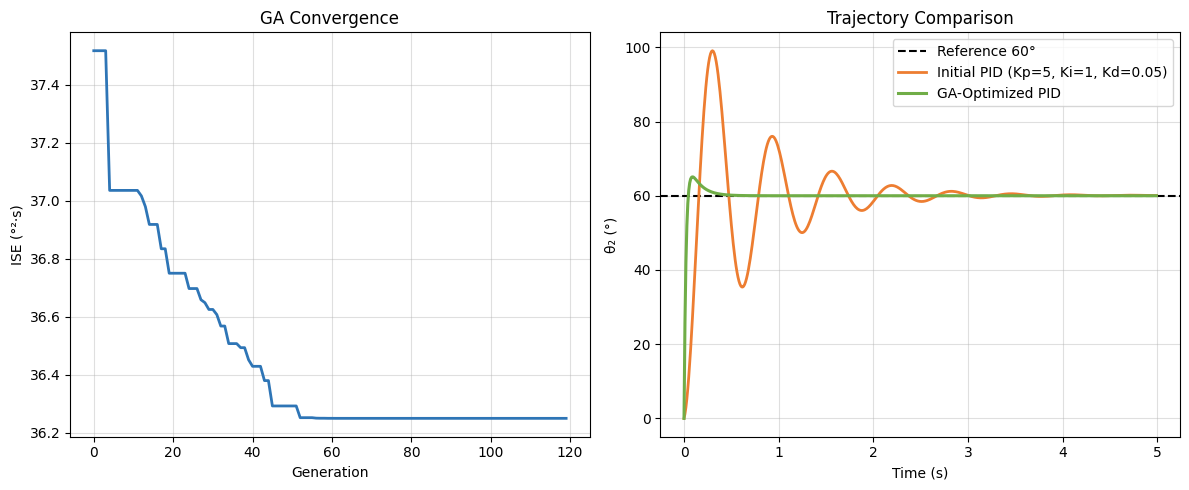

In [4]:
t_sim = arange(0, 5.0, 0.01)

def sim_pid_traj(Kp, Ki, Kd):
    I, b = 0.05, 0.10; dt = 0.01
    t = arange(0, 5.0, dt)
    th = zeros(len(t)); om = zeros(len(t))
    ei, ep = 0.0, 0.0; ref = pi/3
    for k in range(1, len(t)):
        e = ref - th[k-1]; ei += e*dt; de = (e-ep)/dt
        u = Kp*e + Ki*ei + Kd*de
        al = (u-b*om[k-1])/I
        om[k] = om[k-1]+al*dt; th[k] = th[k-1]+om[k]*dt; ep = e
    return t, th

t_b, th_b = sim_pid_traj(5.0, 1.0, 0.05)
t_o, th_o = sim_pid_traj(Kp_opt, Ki_opt, Kd_opt)

fig, axes = plt.subplots(1, 2, figsize=(12, 5))
axes[0].plot(best_ise_hist, color='#2E75B6', lw=2)
axes[0].set_xlabel('Generation')
axes[0].set_ylabel('ISE (°²·s)')
axes[0].set_title('GA Convergence')
axes[0].grid(alpha=0.4)

axes[1].axhline(60, color='k', ls='--', lw=1.5, label='Reference 60°')
axes[1].plot(t_b, degrees(th_b), color='#ED7D31', lw=2, label='Initial PID (Kp=5, Ki=1, Kd=0.05)')
axes[1].plot(t_o, degrees(th_o), color='#70AD47', lw=2.2, label='GA-Optimized PID')
axes[1].set_xlabel('Time (s)')
axes[1].set_ylabel('θ₂ (°)')
axes[1].set_title('Trajectory Comparison')
axes[1].legend()
axes[1].grid(alpha=0.4)
plt.tight_layout()
plt.show()